# E-Sight 근골격계 라벨 데이터 정리

**목적:** 실습 데이터 `반려동물_근골격_데이터_고양이_강아지.zip`(2.8GB)에서 이미지는 제외하고 라벨(JSON)만 꺼내, 분석용 CSV(`musculoskeletal_labels.csv`)로 정리한다.

**원본 출처:** AI Hub「반려동물 질병 진단을 위한 영상 데이터 (근골격계)」 중 일부 (실습용 16,618건)

**사용법:** 1단계 셀의 `zip_path`만 각자 컴퓨터의 zip 경로로 바꾸고 위에서부터 차례로 실행

> ⚠️ 공개 데이터라도 학습 목적으로만 사용하고, 데이터 파일(zip·CSV)은 GitHub 등 외부에 올리지 않기

## 1단계. zip 안의 파일 구성 미리 보기

In [1]:
# zip 안의 파일 구성 미리 보기 (압축은 풀지 않음)


# zipfile: zip 파일을 열고 안의 목록을 읽는 파이썬 기본 도구
import zipfile
# Counter: 항목별 개수를 세어주는 도구
from collections import Counter

# ★ 각자 컴퓨터에서 zip 파일 위치로 바꿔서 실행
# r"...": 앞의 r은 경로 속 역슬래시(\)를 특수문자로 해석하지 말라는 표시
# 탐색기에서 zip 파일 우클릭 → "경로로 복사" 후 r 바로 뒤에 붙여넣기
zip_path = r"여기에_반려동물_근골격_데이터_고양이_강아지.zip_경로_붙여넣기"

# zip 파일을 열고, 블록이 끝나면 자동으로 닫음
with zipfile.ZipFile(zip_path) as zf:
    # namelist(): zip 안의 모든 파일 경로 목록 (압축 해제 없이 읽음)
    names = zf.namelist()
    # 전체 파일 수 출력
    print("전체 파일 수:", len(names))
    # 확장자별 개수 출력 (예: jpg 몇 개, json 몇 개)
    print(Counter(n.rsplit(".", 1)[-1].lower() for n in names if "." in n))
    # 앞쪽 20개 경로만 출력해서 폴더 구조 확인
    for n in names[:20]:
        print(n)


# → zip을 열어서 파일이 전부 몇 개인지 세겠다
# → 확장자별로 몇 개씩 있는지 확인해서, 라벨이 어떤 형식인지 알아내겠다
# → 앞부분 20개 경로를 보고 이미지와 라벨이 어떤 폴더에 나뉘어 있는지 파악하겠다


FileNotFoundError: [Errno 2] No such file or directory: '여기에_반려동물_근골격_데이터_고양이_강아지.zip_경로_붙여넣기'

## 2단계. 라벨 zip만 꺼내기 (이미지 원천데이터는 제외)

In [ ]:
# 안쪽 zip 용량 확인 후 라벨 zip만 꺼내기


# 꺼낸 파일을 저장할 폴더: zip과 같은 폴더 안에 labels 폴더를 만듦
# os.path.dirname(경로): 파일 경로에서 폴더 부분만 잘라냄
import os
out_dir = os.path.join(os.path.dirname(zip_path), "labels")

with zipfile.ZipFile(zip_path) as zf:
    # infolist(): 파일 목록과 함께 크기 등 상세 정보를 가져옴
    for info in zf.infolist():
        # file_size: 압축 풀었을 때 크기(바이트) → 1024를 3번 나눠 GB 단위로 표시
        print(f"{info.filename:35s} {info.file_size / 1024**3:6.2f} GB")
    # 라벨링데이터 폴더 안의 zip 파일만 골라냄
    label_zips = [n for n in zf.namelist()
                  if n.startswith("라벨링데이터/") and n.endswith(".zip")]
    # 골라낸 파일만 out_dir에 꺼냄 (원천데이터 이미지는 건드리지 않음)
    zf.extractall(out_dir, members=label_zips)

print("꺼낸 위치:", out_dir)


# → zip 안의 4개 파일이 각각 몇 GB인지 먼저 보여주겠다
# → 그중 '라벨링데이터/' 안의 VL1_CAT.zip, VL2_DOG.zip만 골라 labels 폴더에 꺼내겠다
# → 용량이 큰 원천데이터(이미지)는 꺼내지 않으니 빠르게 끝난다

## 3단계. 라벨 zip 구성과 샘플 확인

In [ ]:
# 라벨 zip 안의 파일 구성과 샘플 라벨 내용 확인


# 꺼낸 라벨 zip 두 개의 경로
label_dir = os.path.join(out_dir, "라벨링데이터")
label_paths = [os.path.join(label_dir, f) for f in ["VL1_CAT.zip", "VL2_DOG.zip"]]

for p in label_paths:
    with zipfile.ZipFile(p) as lz:
        # 폴더(끝이 '/')는 빼고 실제 파일만 목록으로 만듦
        files = [n for n in lz.namelist() if not n.endswith("/")]
        # os.path.basename(p): 경로에서 파일 이름만 꺼냄
        print("=====", os.path.basename(p), "파일 수:", len(files))
        print(Counter(n.rsplit(".", 1)[-1].lower() for n in files))
        # 앞쪽 5개 경로만 보기
        for n in files[:5]:
            print("  ", n)
        # 첫 번째 파일 내용을 열어서 앞부분 1500자만 출력
        # read(): 파일 내용을 바이트로 읽음 → decode("utf-8"): 사람이 읽는 글자로 변환
        # errors="replace": 깨진 글자가 있어도 멈추지 않고 대체 문자로 표시
        sample = lz.read(files[0]).decode("utf-8", errors="replace")
        print(sample[:1500])
        print()


# → 고양이·강아지 라벨 zip 각각에 파일이 몇 개인지, 어떤 형식인지 세겠다
# → 파일 경로 앞부분 5개를 보고 폴더가 어떻게 나뉘어 있는지 파악하겠다
# → 첫 번째 라벨 파일을 열어, 어떤 항목(축종·부위·정상/이상 등)이 들어 있는지 직접 보겠다

## 4단계. 라벨 JSON 구조 자세히 보기

In [ ]:
# 라벨 JSON 하나를 보기 좋게 출력 + txt 설명서 확인


# json: JSON 형식의 글자를 파이썬 딕셔너리(키:값 묶음)로 바꿔주는 기본 도구
import json

# 고양이 라벨 zip(VL1_CAT.zip)을 열기
with zipfile.ZipFile(label_paths[0]) as lz:
    files = [n for n in lz.namelist() if not n.endswith("/")]

    # txt 파일(설명서로 추정)만 골라서 내용 출력
    for n in files:
        if n.lower().endswith(".txt"):
            print("===== 설명서:", n)
            print(lz.read(n).decode("utf-8", errors="replace")[:2000])

    # 첫 번째 JSON 파일을 읽어서 딕셔너리로 변환
    first_json = [n for n in files if n.lower().endswith(".json")][0]
    data = json.loads(lz.read(first_json).decode("utf-8"))
    # indent=2: 한 단계 들어갈 때마다 2칸 들여쓰기
    # ensure_ascii=False: 한글을 \uXXXX 같은 코드 대신 그대로 보여줌
    print("===== 라벨 예시:", first_json)
    print(json.dumps(data, indent=2, ensure_ascii=False)[:3000])


# → 고양이 라벨 zip에 들어 있는 txt 설명서 내용을 먼저 보겠다
# → 첫 번째 JSON 라벨을 줄바꿈·들여쓰기해서, 어떤 항목이 어떤 구조로 있는지 한눈에 보겠다


## 5단계. 전체 라벨을 하나의 표로 만들어 CSV 저장

In [ ]:
# 고양이·강아지 전체 라벨을 하나의 표로 만들어 CSV로 저장


# pandas: 표 형태 데이터를 다루는 도구
import pandas as pd

# 한 행(영상 1장)씩 담을 빈 리스트
rows = []
for p in label_paths:
    with zipfile.ZipFile(p) as lz:
        for n in lz.namelist():
            # JSON 파일만 처리 (폴더, test.txt 제외)
            if not n.lower().endswith(".json"):
                continue
            d = json.loads(lz.read(n).decode("utf-8"))
            # metadata 항목 전체를 복사해서 한 행으로 사용
            row = dict(d["metadata"])
            row["fileName"] = d["fileName"]
            # 부위 표시 박스가 몇 개인지 새 열로 추가
            row["n_boxes"] = len(d.get("annotations", []))
            rows.append(row)

# 리스트를 표로 변환
df = pd.DataFrame(rows)
# 문자열 날짜를 날짜 형식으로 변환 (errors="coerce": 잘못된 값은 빈칸 NaT로)
df["Birth"] = pd.to_datetime(df["Birth"], format="%Y%m%d", errors="coerce")
df["Date"] = pd.to_datetime(df["Date"], format="%Y%m%d", errors="coerce")
# 촬영일 - 생년월일 = 나이(일 단위) → 365.25로 나눠 년 단위로
df["age_years"] = ((df["Date"] - df["Birth"]).dt.days / 365.25).round(1)

# 결과를 CSV로 저장 (utf-8-sig: 엑셀에서 열어도 한글이 안 깨지게)
csv_path = os.path.join(os.path.dirname(zip_path), "musculoskeletal_labels.csv")
df.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(df.shape)
print(df.head())
print(df["Disease"].value_counts())


# → 고양이·강아지 라벨 JSON 16,618개를 하나씩 열어 metadata를 한 행으로 모으겠다
# → 날짜를 계산 가능한 형식으로 바꾸고, 촬영 당시 나이(년)를 새 변수로 만들겠다
# → 완성된 표를 CSV로 저장해서 팀원들과 공유하고 분석에 바로 쓰겠다
# → 표 크기, 앞부분 5행, 정상/이상 개수를 출력해 제대로 만들어졌는지 확인하겠다

## 6단계. 데이터 품질 점검과 기본 층별화

In [ ]:
# 데이터 품질 점검과 기본 층별화 표


# 1) 생년월일 기본값 의심: 가장 많이 나온 생년월일 상위 5개와 비율
print("===== 생년월일 상위 5개 (축종별)")
for sp in ["C", "D"]:
    # normalize=True: 개수 대신 비율로 표시
    print(sp, df.loc[df["Species"] == sp, "Birth"].value_counts(normalize=True).head(5).round(3), sep="\n")

# 2) 축종별 정상/이상 개수와 이상 비율
# crosstab: 두 변수를 교차해서 개수를 세는 표 / margins=True: 합계 행·열 추가
print("===== 축종 × 정상/이상")
print(pd.crosstab(df["Species"], df["Disease"], margins=True))
# groupby 후 (Disease == "ABN")의 평균 = 이상소견 비율
print((df["Disease"] == "ABN").groupby(df["Species"]).mean().round(3))

# 3) 질환 코드가 정상/이상 모두에 붙는지 확인
print("===== 질환 코드 × 정상/이상")
print(pd.crosstab(df["Disease-Name"], df["Disease"]))

# 4) 촬영 방향, 병원 수, 촬영 연도 범위
print("===== 촬영 방향")
print(df["Position"].value_counts())
print("병원 수:", df["Hospital-id"].nunique())
print("촬영 연도:", df["Date"].dt.year.min(), "~", df["Date"].dt.year.max())


# → 생년월일 중 특정 값이 비정상적으로 많은지 봐서, 나이 변수를 써도 되는지 판단하겠다
# → 고양이·강아지별 이상소견 비율을 정확히 계산하겠다 (발표의 '불균형' 근거)
# → 질환 코드가 정상 영상에도 붙는지 확인해서, 코드의 진짜 의미를 파악하겠다
# → 촬영 방향·병원 수·촬영 기간을 보고 어떤 기준으로 층별화할 수 있는지 정하겠다

## 7단계. 질환군별 이상소견 비율

In [ ]:
# 질환군 코드 → 질환명 매핑 후 질환군별 이상소견 비율 표


# AI Hub 원본 데이터(반려동물 질병 진단을 위한 영상 데이터 - 근골격계) 코드표 기준
# Disease-Name은 '진단된 병'이 아니라 '어떤 질환을 의심해 촬영했는지'를 뜻함
code_map = {
    "Mu01": "골격계종양",
    "Mu02": "사지골절",
    "Mu03": "갈비뼈골절",
    "Mu04": "엉덩관절탈구",
    "Mu05": "슬개골탈구",
    "Mu06": "전십자인대파열",
    "Mu07": "추간판질환",
}
# map(): 각 코드를 딕셔너리에서 찾아 질환명으로 바꿔 새 열로 추가
df["disease_kr"] = df["Disease-Name"].map(code_map)

# 질환군별로 묶어서 전체 건수, 이상 건수, 이상 비율 계산
# agg(): 묶은 그룹마다 여러 계산을 한 번에 수행
summary = (df.assign(is_abn=(df["Disease"] == "ABN"))
             .groupby(["Disease-Name", "disease_kr"])
             .agg(전체=("is_abn", "size"), 이상=("is_abn", "sum"), 이상비율=("is_abn", "mean")))
# 이상 건수가 전체 이상소견 중 몇 %를 차지하는지
summary["이상소견중_비중"] = summary["이상"] / summary["이상"].sum()
# 비율 두 열을 %로 보기 좋게 반올림
summary[["이상비율", "이상소견중_비중"]] = (summary[["이상비율", "이상소견중_비중"]] * 100).round(1)
# 이상 비율이 높은 순서로 정렬
print(summary.sort_values("이상비율", ascending=False))


# → 질환군 코드(Mu01~07)를 한글 질환명으로 바꿔 새 열을 만들겠다
# → 질환군마다 전체 영상 수, 이상 영상 수, 이상 비율(%)을 계산하겠다
# → 각 질환군이 전체 이상소견 중 몇 %를 차지하는지도 함께 보겠다
# → 이상 비율이 높은 순서로 정렬해서 선별(triage) 우선순위 근거로 쓰겠다


## 정리: 주요 발견

| 항목 | 내용 |
| --- | --- |
| 규모 | 총 16,618장 (강아지 15,014 / 고양이 1,604) |
| 이상소견 | 강아지 1,724건(11.5%) / 고양이 26건(1.6%) |
| 질환군별 이상 비율 | 슬개골탈구 47.2% · 엉덩관절탈구 12.9% · 사지골절 5.2% · 전십자인대파열 3.9% · 추간판질환 2.7% · 갈비뼈골절 2.3% · 골격계종양 0.3% |
| 이상소견 집중도 | 전체 이상 1,750건 중 67%(1,180건)가 슬개골탈구 |
| 층별화 가능 변수 | 축종, 질환군(7), 성별(4), 나이, 병원(21곳), 촬영 방향(AP·ML·Lateral·VD), 촬영 연도(2004~2021) |
| 없는 변수 | 품종, 체중 → 분석계획서 수정 필요 |
| 결합키 | 동물 ID 없음 → 영상 단위 `fileName` 또는 `Annotation-id` 사용 |

**메시지 방향:** 질환군마다 이상 비율이 최대 약 150배 차이 나고 이상소견이 한 질환군에 몰려 있다 → "먼저 볼 영상을 골라주는 선별 기능"의 근거. 골격계종양처럼 드물지만 위험한 케이스를 걸러주는 안전망 역할도 제시 가능.

**다음 분석:** 병원·촬영 방향·나이별 이상 비율, 카이제곱 검정

In [2]:
# 층별 이상소견 비율과 카이제곱 검정


# pandas: 표 데이터 도구 / numpy: 수치 계산 도구
import pandas as pd
import numpy as np
# chi2_contingency: 교차표를 넣으면 카이제곱 검정 결과를 계산해주는 함수
from scipy.stats import chi2_contingency

# CSV 불러오기 (노트북과 같은 폴더에 있다고 가정)
# dtype=str: 병원 번호·어노테이션 번호의 앞자리 0을 유지
df = pd.read_csv("musculoskeletal_labels.csv", dtype={"Hospital-id": str, "Annotation-id": str})

# 목표 변수: 이상(ABN)이면 1, 정상이면 0
df["is_abn"] = (df["Disease"] == "ABN").astype(int)
# Sex에서 성별과 중성화 여부를 분리 (C로 시작하면 중성화 수컷, S로 시작하면 중성화 암컷)
df["neuter_yn"] = df["Sex"].str[0].isin(["C", "S"]).map({True: "Y", False: "N"})
# pd.cut: 나이를 구간으로 나눔 (right=False: 왼쪽 값 포함, 예: 1살은 '1-3살'에 들어감)
df["age_group"] = pd.cut(df["age_years"], bins=[0, 1, 3, 7, 10, 100],
                         labels=["1살 미만", "1-3살", "3-7살", "7-10살", "10살 이상"], right=False)
# 촬영 연도만 뽑아서 5년 단위 구간으로 묶음
df["year_group"] = pd.cut(pd.to_datetime(df["Date"]).dt.year, bins=[2000, 2010, 2015, 2020, 2022],
                          labels=["~2009", "2010-14", "2015-19", "2020-21"], right=False)

# 나이가 음수이거나 비어 있는 이상한 값이 있는지 먼저 확인
print("나이 범위:", df["age_years"].min(), "~", df["age_years"].max(), "/ 구간 밖:", df["age_group"].isna().sum())

# 검정할 변수 목록 (변수명: 화면에 보일 이름)
targets = {"Species": "축종", "Sex": "성별", "neuter_yn": "중성화", "age_group": "나이대",
           "Position": "촬영 자세", "Hospital-id": "병원", "year_group": "촬영 연도", "Disease-Name": "질환군"}

results = []
for col, name in targets.items():
    # 변수 값 × 정상/이상 교차표
    table = pd.crosstab(df[col], df["is_abn"])
    # 카이제곱 검정: chi2(검정통계량), p(p-value), dof(자유도), expected(기대빈도)
    chi2, p, dof, expected = chi2_contingency(table)
    # 크래머 V = √(chi2 ÷ (전체 건수 × (행·열 중 작은 쪽 개수 − 1)))
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    # 그룹별 이상 비율의 최솟값·최댓값 (%)
    rate = df.groupby(col, observed=True)["is_abn"].mean() * 100
    results.append([name, table.shape[0], round(rate.min(), 1), round(rate.max(), 1), f"{p:.1e}", round(v, 3)])

# 결과를 표로 만들고, 관련 강도(크래머 V)가 큰 순서로 정렬
res = pd.DataFrame(results, columns=["변수", "그룹 수", "최저 이상률(%)", "최고 이상률(%)", "p-value", "크래머 V"])
print(res.sort_values("크래머 V", ascending=False).to_string(index=False))


# → CSV를 새로 불러와 이상 여부(0/1), 중성화 여부, 나이대, 촬영 연도대를 새 변수로 만들겠다
# → 나이 값에 이상한 값(음수, 구간 밖)이 있는지 먼저 확인하겠다
# → 8개 변수 각각에 대해 그룹별 이상 비율의 최저~최고 범위를 구하겠다
# → 카이제곱 검정으로 차이가 우연인지(p-value), 관련이 얼마나 강한지(크래머 V)를 함께 보겠다
# → 관련이 강한 변수 순서로 정렬해, 층별화에서 어떤 기준이 가장 중요한지 한눈에 보겠다

나이 범위: 0.0 ~ 21.3 / 구간 밖: 0
   변수  그룹 수  최저 이상률(%)  최고 이상률(%)  p-value  크래머 V
  질환군     7        0.3       47.2  0.0e+00  0.513
촬영 자세     4        2.4       24.5  0.0e+00  0.334
   병원    21        0.0       66.7 4.0e-156  0.219
   축종     2        1.6       11.5  3.6e-34  0.095
촬영 연도     4        1.7       11.7  8.4e-31  0.093
  나이대     5        0.0       19.4  1.0e-16  0.070
   성별     4        9.0       12.6  1.9e-07  0.045
  중성화     2        9.7       12.3  5.8e-07  0.039


In [3]:
# 촬영 자세·병원 효과가 질환군 때문인지 확인 (교란 점검)


# 1) 질환군 × 촬영 자세 교차표: 질환군마다 주로 어떤 자세로 찍는지 (행 기준 비율 %)
# normalize="index": 각 행(질환군)의 합이 100%가 되도록 비율 계산
print("===== 질환군별 촬영 자세 구성 (%)")
print((pd.crosstab(df["Disease-Name"], df["Position"], normalize="index") * 100).round(1))

# 2) 같은 질환군 안에서 자세별 이상률 비교 (질환군을 고정하면 자세 효과가 남는지)
# pivot_table: 행=질환군, 열=자세, 값=이상 비율 평균
print("===== 질환군 안에서 자세별 이상률 (%)")
print((df.pivot_table(index="Disease-Name", columns="Position", values="is_abn", aggfunc="mean") * 100).round(1))

# 3) 병원별 촬영 건수, 이상률, 가장 많이 찍은 질환군과 그 비중
# agg: 병원별로 여러 값을 한 번에 계산 / lambda: 즉석에서 만드는 작은 함수
hosp = df.groupby("Hospital-id").agg(
    건수=("is_abn", "size"),
    이상률=("is_abn", "mean"),
    주요질환군=("Disease-Name", lambda s: s.value_counts().index[0]),
    주요질환군_비중=("Disease-Name", lambda s: s.value_counts(normalize=True).iloc[0]),
)
hosp[["이상률", "주요질환군_비중"]] = (hosp[["이상률", "주요질환군_비중"]] * 100).round(1)
print("===== 병원별 현황 (이상률 높은 순)")
print(hosp.sort_values("이상률", ascending=False).to_string())


# → 질환군마다 어떤 촬영 자세를 주로 쓰는지 보고, 자세와 질환군이 얽혀 있는지 확인하겠다
# → 질환군을 고정한 상태에서도 자세별 이상률 차이가 남는지 보겠다 (남으면 자세 자체 효과)
# → 병원별 촬영 건수와 주요 질환군을 보고, 이상률 차이가 환자 구성 때문인지 확인하겠다


===== 질환군별 촬영 자세 구성 (%)
Position        AP  Lateral    ML    VD
Disease-Name                           
Mu01          21.8     17.3  59.3   1.5
Mu02          47.8      0.0  52.1   0.0
Mu03           0.0     36.8   0.0  63.2
Mu04          91.9      0.1   0.1   7.9
Mu05          99.4      0.1   0.3   0.2
Mu06           0.2      0.4  99.4   0.0
Mu07           0.1     99.1   0.5   0.4
===== 질환군 안에서 자세별 이상률 (%)
Position        AP  Lateral    ML    VD
Disease-Name                           
Mu01           0.7      0.0   0.3   0.0
Mu02           4.2      0.0   6.1   0.0
Mu03           NaN      2.8   0.0   2.0
Mu04          13.4      0.0   0.0   6.6
Mu05          47.2      0.0  57.1  60.0
Mu06           0.0     10.0   3.9   NaN
Mu07           0.0      2.6  20.0  12.5
===== 병원별 현황 (이상률 높은 순)
               건수   이상률 주요질환군  주요질환군_비중
Hospital-id                            
0017            6  66.7  Mu05      66.7
0021           36  25.0  Mu05      33.3
0032         2624  23.9  Mu03      38.5
0004  

In [4]:
# 병원별 기대 이상률 대비 실제 이상률 (질환군 구성을 감안한 비교)


# 질환군별 전체 이상률 (예: Mu05 → 0.472)
group_rate = df.groupby("Disease-Name")["is_abn"].mean()
# 영상 한 장마다 '그 질환군의 평균 이상률'을 기대값으로 붙임
df["expected"] = df["Disease-Name"].map(group_rate)

# 병원별로 건수, 실제 이상률, 기대 이상률 계산
oe = df.groupby("Hospital-id").agg(건수=("is_abn", "size"),
                                  실제=("is_abn", "mean"),
                                  기대=("expected", "mean"))
# 촬영 100장 미만 병원은 비율이 불안정하므로 제외
oe = oe[oe["건수"] >= 100].copy()
# O/E 비율 = 실제 ÷ 기대 (1보다 크면 질환군 구성을 감안해도 이상 판정이 많음)
oe["O/E"] = (oe["실제"] / oe["기대"]).round(2)
oe[["실제", "기대"]] = (oe[["실제", "기대"]] * 100).round(1)
print(oe.sort_values("O/E", ascending=False).to_string())
print("O/E 최대 ÷ 최소:", round(oe["O/E"].max() / oe["O/E"].min(), 1), "배")


# → 질환군별 평균 이상률을 구해, 각 영상에 '이 질환군이면 보통 이 정도'라는 기대값을 붙이겠다
# → 병원마다 기대 이상률(질환군 구성 기준)과 실제 이상률을 나란히 계산하겠다
# → 100장 미만 병원은 빼고, 실제 ÷ 기대(O/E)로 환자 구성을 감안한 병원 간 차이를 보겠다
# → O/E가 가장 큰 병원과 작은 병원이 몇 배 차이 나는지 확인하겠다

               건수    실제    기대   O/E
Hospital-id                        
0004          126  23.8  11.5  2.07
0011          761  14.5   8.6  1.68
0032         2624  23.9  15.7  1.53
0013          992   8.9   6.5  1.36
0009         1707   9.4   8.5  1.10
0014         3595   9.9  11.3  0.87
0018          304   3.6   4.2  0.86
0002          157  12.1  14.7  0.82
0020         3122   6.8   8.7  0.78
0016          222   7.2  10.6  0.68
0030         2057   4.4  10.8  0.41
0028          490   1.2   9.7  0.13
0029          290   0.7   7.9  0.09
O/E 최대 ÷ 최소: 23.0 배


In [5]:
# 질환군 + 축종까지 감안한 병원별 O/E 재계산


# 질환군 × 축종 조합별 평균 이상률 (예: (Mu05, D) → 강아지 슬개골탈구의 이상률)
# transform("mean"): 그룹 평균을 계산해 원래 행 개수 그대로 각 행에 붙여줌
df["expected2"] = df.groupby(["Disease-Name", "Species"])["is_abn"].transform("mean")

# 병원별 건수, 고양이 비중, 실제 이상률, 두 가지 기대 이상률 계산
oe2 = df.groupby("Hospital-id").agg(건수=("is_abn", "size"),
                                   고양이비중=("Species", lambda s: (s == "C").mean()),
                                   실제=("is_abn", "mean"),
                                   기대_질환군=("expected", "mean"),
                                   기대_질환군축종=("expected2", "mean"))
# 100장 미만 병원 제외
oe2 = oe2[oe2["건수"] >= 100].copy()
# 이전 방식 O/E와 새 방식 O/E를 나란히 계산
oe2["O/E_이전"] = (oe2["실제"] / oe2["기대_질환군"]).round(2)
oe2["O/E_보정"] = (oe2["실제"] / oe2["기대_질환군축종"]).round(2)
# 비율 컬럼은 %로 보기 좋게
pct_cols = ["고양이비중", "실제", "기대_질환군", "기대_질환군축종"]
oe2[pct_cols] = (oe2[pct_cols] * 100).round(1)
print(oe2.sort_values("O/E_보정", ascending=False).to_string())
print("보정 후 O/E 최대 ÷ 최소:", round(oe2["O/E_보정"].max() / oe2["O/E_보정"].min(), 1), "배")

# 1,000장 이상 큰 병원끼리만 비교
big = oe2[oe2["건수"] >= 1000]
print("1,000장 이상 병원 O/E 최대 ÷ 최소:", round(big["O/E_보정"].max() / big["O/E_보정"].min(), 1), "배")


# → 질환군과 축종을 함께 고려한 조합별 이상률을 각 영상의 기대값으로 붙이겠다
# → 병원마다 고양이 비중을 같이 보여줘서, 축종 구성이 결과에 영향을 줬는지

               건수  고양이비중    실제  기대_질환군  기대_질환군축종  O/E_이전  O/E_보정
Hospital-id                                                     
0004          126   60.3  23.8    11.5      10.4    2.07    2.28
0011          761    4.7  14.5     8.6       8.6    1.68    1.67
0032         2624    6.0  23.9    15.7      15.7    1.53    1.52
0013          992    3.9   8.9     6.5       6.6    1.36    1.34
0009         1707   21.6   9.4     8.5       8.3    1.10    1.13
0018          304   20.1   3.6     4.2       4.1    0.86    0.87
0014         3595    3.1   9.9    11.3      11.4    0.87    0.86
0002          157   12.7  12.1    14.7      14.2    0.82    0.85
0020         3122   14.1   6.8     8.7       8.6    0.78    0.79
0016          222    1.8   7.2    10.6      10.6    0.68    0.68
0030         2057   13.7   4.4    10.8      10.8    0.41    0.40
0028          490    0.0   1.2     9.7       9.9    0.13    0.12
0029          290    2.1   0.7     7.9       7.9    0.09    0.09
보정 후 O/E 최대 ÷ 최소: 25.3 배


In [7]:
# 그래프 공통 설정: 한글 글꼴, 저장 폴더, 질환명 매핑


# matplotlib.pyplot: 파이썬 기본 그래프 도구
import matplotlib.pyplot as plt
import os

# 윈도우 기본 한글 글꼴(맑은 고딕) 지정 → 지정 안 하면 한글이 네모(□)로 깨짐
plt.rcParams["font.family"] = "Malgun Gothic"
# 한글 글꼴에서 마이너스(-) 기호가 깨지는 문제 방지
plt.rcParams["axes.unicode_minus"] = False
# 그래프 저장 폴더 생성 (exist_ok=True: 이미 있으면 그냥 넘어감)
os.makedirs("figures", exist_ok=True)

# 질환군 코드 → 한글 질환명
code_map = {"Mu01": "골격계종양", "Mu02": "사지골절", "Mu03": "갈비뼈골절", "Mu04": "엉덩관절탈구",
            "Mu05": "슬개골탈구", "Mu06": "전십자인대파열", "Mu07": "추간판질환"}


# → 한글이 깨지지 않도록 글꼴을 맑은 고딕으로 설정하겠다
# → 완성된 그래프를 모아둘 figures 폴더를 만들겠다
# → 그래프에 코드 대신 한글 질환명을 쓰기 위해 매핑 사전을 준비하겠다

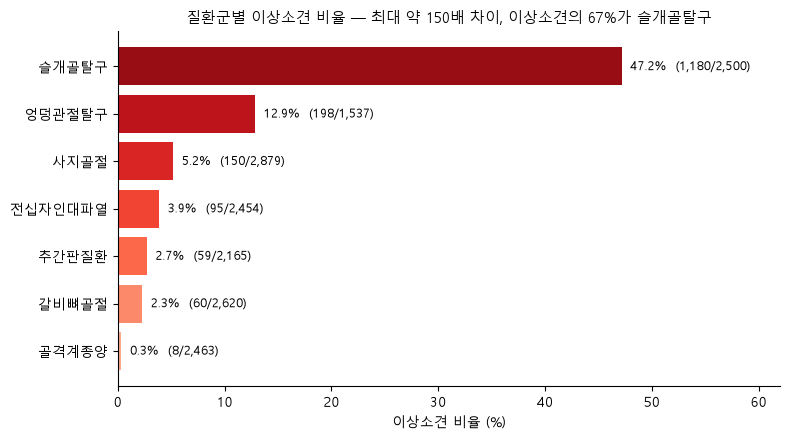

In [8]:
# 그래프 1: 질환군별 이상소견 비율


# 질환군별 이상 비율(mean), 전체 건수(size), 이상 건수(sum)를 한 번에 계산
rate = df.groupby("Disease-Name")["is_abn"].agg(["mean", "size", "sum"])
# 코드를 한글 질환명으로 변환
rate["name"] = rate.index.map(code_map)
# 이상 비율이 낮은 순 정렬 → 가로 막대에서 위쪽에 높은 값이 오게 됨
rate = rate.sort_values("mean")

# np.linspace(0.3, 0.9, 7): 0.3~0.9를 7등분 → 값이 클수록 진한 빨강
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(rate)))
# figsize=(가로, 세로) 인치 단위 그래프 크기
fig, ax = plt.subplots(figsize=(8, 4.5))
# barh: 가로 막대그래프 (세로축=질환명, 가로축=비율%)
bars = ax.barh(rate["name"], rate["mean"] * 100, color=colors)
# 막대 오른쪽 끝에 '비율% (이상/전체)' 글자 표시
for bar, (m, n, s) in zip(bars, rate[["mean", "size", "sum"]].values):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
            f"{m*100:.1f}%  ({int(s):,}/{int(n):,})", va="center", fontsize=9)

ax.set_xlabel("이상소견 비율 (%)")
ax.set_xlim(0, 62)
ax.set_title("질환군별 이상소견 비율 — 최대 약 150배 차이, 이상소견의 67%가 슬개골탈구", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
# dpi=200: 슬라이드에 넣어도 흐리지 않은 해상도로 저장
plt.savefig("figures/01_질환군별_이상률.png", dpi=200)
plt.show()


# → 질환군마다 이상 비율과 건수를 계산해 한글 질환명으로 바꾸겠다
# → 이상 비율이 높을수록 진한 빨간색 가로 막대로 그려, 차이가 한눈에 보이게 하겠다
# → 막대 끝에 비율과 '이상 건수/전체 건수'를 적어 근거 숫자를 같이 보여주겠다
# → 슬라이드용으로 figures 폴더에 고해상도 PNG로 저장하겠다

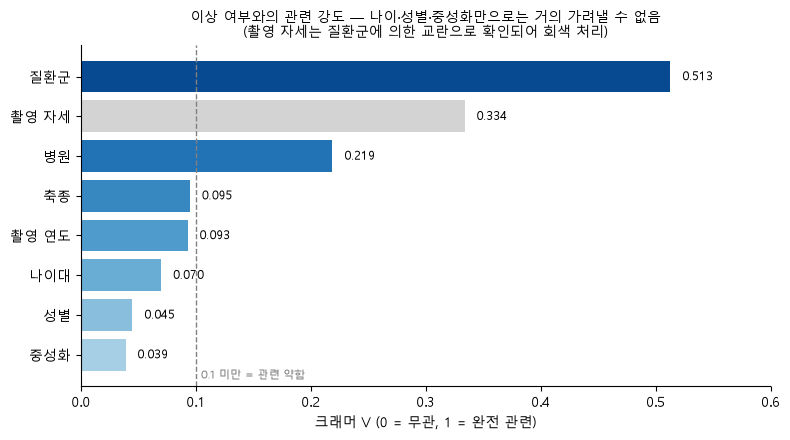

In [9]:
# 그래프 2: 이상 여부와 각 변수의 관련 강도(크래머 V)


# 크래머 V가 작은 순 정렬 → 위쪽에 강한 변수가 오게 됨
r = res.sort_values("크래머 V")
# 기본 파란색 계열 색을 만들고, 교란으로 확인된 '촬영 자세'만 회색으로 바꿈
base = plt.cm.Blues(np.linspace(0.35, 0.9, len(r)))
colors = ["lightgray" if name == "촬영 자세" else c for name, c in zip(r["변수"], base)]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(r["변수"], r["크래머 V"], color=colors)
for bar, v in zip(bars, r["크래머 V"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
# axvline: 세로 기준선 (0.1 미만 = 관련 약함)
ax.axvline(0.1, color="gray", linestyle="--", linewidth=1)
ax.text(0.105, -0.6, "0.1 미만 = 관련 약함", color="gray", fontsize=8)

ax.set_xlabel("크래머 V (0 = 무관, 1 = 완전 관련)")
ax.set_xlim(0, 0.6)
ax.set_title("이상 여부와의 관련 강도 — 나이·성별·중성화만으로는 거의 가려낼 수 없음\n(촬영 자세는 질환군에 의한 교란으로 확인되어 회색 처리)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/02_변수별_관련강도.png", dpi=200)
plt.show()


# → 8개 변수의 크래머 V를 강한 순서대로 파란 가로 막대로 그리겠다
# → 교란으로 판명된 촬영 자세는 회색으로 표시해, 해석에서 제외했다는 걸 보여주겠다
# → 0.1 기준선을 그어 나이·성별·중성화가 '약함' 구간에 있다는 걸 강조하겠다

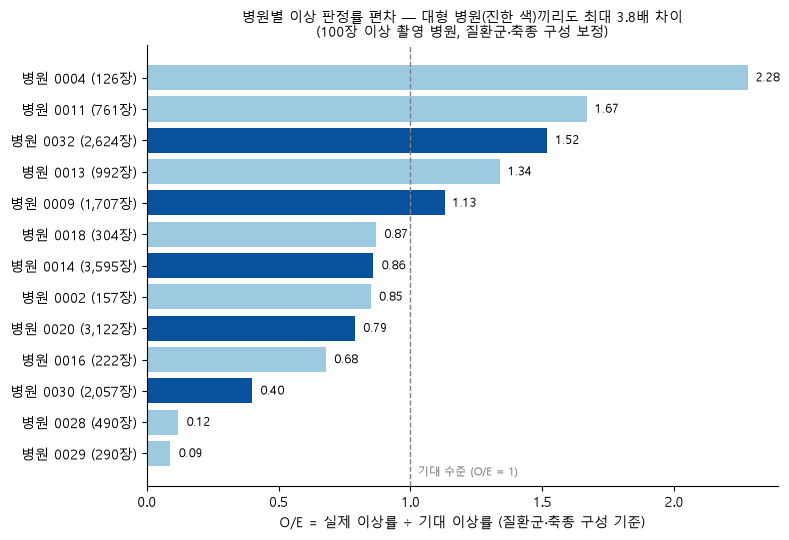

In [10]:
# 그래프 3: 질환군·축종을 감안한 병원별 이상 판정률(O/E)


# O/E가 작은 순 정렬
o = oe2.sort_values("O/E_보정")
# 세로축 이름: '병원 0032 (2,624장)' 형태
labels = [f"병원 {h} ({n:,}장)" for h, n in zip(o.index, o["건수"])]
# 1,000장 이상 대형 병원은 진한 파랑, 나머지는 연한 파랑
colors = ["#08519c" if n >= 1000 else "#9ecae1" for n in o["건수"]]

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(labels, o["O/E_보정"], color=colors)
for bar, v in zip(bars, o["O/E_보정"]):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2, f"{v:.2f}", va="center", fontsize=9)
# O/E = 1 기준선: 질환군·축종 구성으로 기대되는 수준
ax.axvline(1.0, color="gray", linestyle="--", linewidth=1)
ax.text(1.03, -0.7, "기대 수준 (O/E = 1)", color="gray", fontsize=8)

ax.set_xlabel("O/E = 실제 이상률 ÷ 기대 이상률 (질환군·축종 구성 기준)")
ax.set_title("병원별 이상 판정률 편차 — 대형 병원(진한 색)끼리도 최대 3.8배 차이\n(100장 이상 촬영 병원, 질환군·축종 구성 보정)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/03_병원별_OE.png", dpi=200)
plt.show()


# → 병원별 보정 O/E를 가로 막대로 그리고, 병원 이름 옆에 촬영 건수를 적겠다
# → 1,000장 이상 대형 병원은 진한 색으로 구분해, 큰 병원끼리도 차이가 난다는 걸 보여주겠다
# → O/E=1 기준선으로 '기대보다 많이/적게 판정한 병원'을 한눈에 나누겠다